# Domain-Specific Chatbot Finetuning with Mistral-7B
## Cooking Knowledge Assistant

This notebook implements finetuning of Mistral-7B-Instruct-v0.2 using LoRA and quantization for a cooking knowledge chatbot. The model is trained on paragraph-based cooking content (recipes, techniques, tips) and can answer any cooking-related questions.

## 1. Setup and Installation

In [1]:
# Install required packages
!pip install -q transformers accelerate peft bitsandbytes datasets trl torch sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 MB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 465.5/465.5 kB 22.8 MB/s eta 0:00:00


## 1.1 Install RAG Dependencies

For Retrieval-Augmented Generation, we need additional libraries for vector embeddings and similarity search.

In [2]:
# Install RAG-specific packages
!pip install -q sentence-transformers faiss-cpu scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 64.5 MB/s eta 0:00:00


In [3]:
import torch
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    TrainingArguments,
    pipeline
)
from peft import LoraConfig, PeftModel, prepare_model_for_kbit_training, get_peft_model
from trl import SFTTrainer
from datasets import Dataset, load_dataset
import pandas as pd
import numpy as np
import json
from typing import Dict, List
import matplotlib.pyplot as plt

# RAG imports
from sentence_transformers import SentenceTransformer
import faiss
from sklearn.metrics.pairwise import cosine_similarity

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA version: {torch.version.cuda}")
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.9.0+cu126
CUDA available: True
CUDA version: 12.6
GPU: Tesla T4


## 2. Data Processing

We'll load a dataset of cooking knowledge paragraphs covering recipes, techniques, ingredients, and tips.

In [5]:
# Load our custom cooking dataset (paragraph format)
with open('/content/cooking_qa.json', 'r') as f:
    cooking_data = json.load(f)

print(f"Loaded {len(cooking_data)} cooking knowledge paragraphs")
print(f"\nDataset Statistics:")
print(f"  Total paragraphs: {len(cooking_data)}")
print(f"  Training samples (85%): {int(len(cooking_data) * 0.85)}")
print(f"  Validation samples (15%): {len(cooking_data) - int(len(cooking_data) * 0.85)}")
print("\nSample paragraph (first 300 characters):")
print(f"{cooking_data[0]['text'][:300]}...")

Loaded 97 cooking knowledge paragraphs

Dataset Statistics:
  Total paragraphs: 97
  Training samples (85%): 82
  Validation samples (15%): 15

Sample paragraph (first 300 characters):
Classic Italian Risotto is a creamy rice dish from Northern Italy. To make authentic risotto, start with high-quality arborio or carnaroli rice, which has the perfect starch content for creating that signature creamy texture. Begin by heating chicken or vegetable stock in a separate pot and keeping ...


In [6]:
# Format data for instruction tuning
def format_instruction(sample: Dict) -> str:
    """Format cooking paragraph in instruction format for Mistral-7B-Instruct."""
    # The text already contains cooking knowledge, we just wrap it in instruction format
    return f"""<s>[INST] Tell me about cooking techniques and recipes. [/INST] {sample['text']}</s>"""

# Split data into train and validation
train_size = int(0.85 * len(cooking_data))
train_data = cooking_data[:train_size]
val_data = cooking_data[train_size:]

print(f"Training samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")

# Create datasets
train_dataset = Dataset.from_pandas(pd.DataFrame(train_data))
val_dataset = Dataset.from_pandas(pd.DataFrame(val_data))

# Add formatted text column
train_dataset = train_dataset.map(lambda x: {"formatted_text": format_instruction(x)})
val_dataset = val_dataset.map(lambda x: {"formatted_text": format_instruction(x)})

Training samples: 82
Validation samples: 15


Map:   0%|          | 0/82 [00:00<?, ? examples/s]

Map:   0%|          | 0/15 [00:00<?, ? examples/s]

## 2.5 Build RAG Knowledge Base

Create a vector database from our cooking knowledge for retrieval.

In [7]:
# Initialize embedding model for RAG
print("Loading embedding model for RAG...")
embedding_model = SentenceTransformer('all-MiniLM-L6-v2')  # Fast and efficient
print("Embedding model loaded!")

# Create embeddings for all cooking knowledge
print("\nCreating embeddings for cooking knowledge base...")
knowledge_texts = [item['text'] for item in cooking_data]
knowledge_embeddings = embedding_model.encode(knowledge_texts, show_progress_bar=True)

print(f"Created {len(knowledge_embeddings)} embeddings")
print(f"Embedding dimension: {knowledge_embeddings.shape[1]}")

# Build FAISS index for fast similarity search
print("\nBuilding FAISS index...")
dimension = knowledge_embeddings.shape[1]
index = faiss.IndexFlatL2(dimension)  # L2 distance for similarity
index.add(knowledge_embeddings.astype('float32'))

print(f"FAISS index built with {index.ntotal} vectors")
print("RAG knowledge base ready!")

Loading embedding model for RAG...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded!

Creating embeddings for cooking knowledge base...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Created 97 embeddings
Embedding dimension: 384

Building FAISS index...
FAISS index built with 97 vectors
RAG knowledge base ready!


In [8]:
# RAG retrieval function
def retrieve_relevant_knowledge(query: str, top_k: int = 3) -> List[str]:
    """
    Retrieve top-k most relevant cooking knowledge pieces for a query.

    Args:
        query: User's question or topic
        top_k: Number of relevant pieces to retrieve

    Returns:
        List of relevant cooking knowledge texts
    """
    # Encode the query
    query_embedding = embedding_model.encode([query])

    # Search in FAISS index
    distances, indices = index.search(query_embedding.astype('float32'), top_k)

    # Get the relevant texts
    relevant_texts = [knowledge_texts[idx] for idx in indices[0]]

    return relevant_texts, distances[0]

# Test the retrieval
test_query = "How to make risotto?"
retrieved, distances = retrieve_relevant_knowledge(test_query, top_k=3)

print(f"Query: {test_query}\n")
print("Retrieved Knowledge (Top 3):")
for i, (text, dist) in enumerate(zip(retrieved, distances), 1):
    print(f"\n{i}. Distance: {dist:.4f}")
    print(f"   Text preview: {text[:200]}...")


Query: How to make risotto?

Retrieved Knowledge (Top 3):

1. Distance: 0.5303
   Text preview: Classic Italian Risotto is a creamy rice dish from Northern Italy. To make authentic risotto, start with high-quality arborio or carnaroli rice, which has the perfect starch content for creating that ...

2. Distance: 1.1033
   Text preview: Steps for fluffy quinoa: 1) Rinse thoroughly (removes bitter saponin coating). 2) Ratio: 1 cup quinoa to 2 cups liquid. 3) Bring to boil, reduce to simmer, cover. 4) Cook 15 minutes without lifting li...

3. Distance: 1.1156
   Text preview: Use chicken bones/carcass, 2 carrots, 2 celery stalks, 1 onion (quartered), 2 bay leaves, peppercorns, and parsley. Cover with cold water (about 4 quarts). Bring to boil, then simmer on low for 3-4 ho...


## 3. Model Configuration with LoRA and Quantization

In [9]:
# Model configuration
model_name = "mistralai/Mistral-7B-Instruct-v0.2"

# 4-bit quantization configuration
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

print("Loading model with 4-bit quantization...")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

Loading model with 4-bit quantization...


In [10]:
# Load model with quantization
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
)

model = prepare_model_for_kbit_training(model)
print("Model loaded successfully!")

config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/4.54G [00:00<?, ?B/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/4.94G [00:00<?, ?B/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Model loaded successfully!


In [11]:
# LoRA configuration
peft_config = LoraConfig(
    r=16,  # LoRA rank
    lora_alpha=32,  # LoRA scaling factor
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],  # Attention matrices
)

model = get_peft_model(model, peft_config)
model.print_trainable_parameters()

trainable params: 13,631,488 || all params: 7,255,363,584 || trainable%: 0.1879


## 4. Baseline Evaluation (Before Training)

In [12]:
# Evaluation function for perplexity
def calculate_perplexity(model, dataset, tokenizer, max_samples=50):
    """Calculate perplexity on validation dataset."""
    model.eval()
    total_loss = 0
    total_tokens = 0

    eval_samples = min(max_samples, len(dataset))

    with torch.no_grad():
        for i in range(eval_samples):
            text = dataset[i]["formatted_text"]
            inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512).to(model.device)

            outputs = model(**inputs, labels=inputs["input_ids"])
            total_loss += outputs.loss.item() * inputs["input_ids"].size(1)
            total_tokens += inputs["input_ids"].size(1)

    avg_loss = total_loss / total_tokens
    perplexity = np.exp(avg_loss)

    return perplexity, avg_loss

print("Calculating baseline perplexity...")
baseline_perplexity, baseline_loss = calculate_perplexity(model, val_dataset, tokenizer)
print(f"Baseline Perplexity: {baseline_perplexity:.2f}")
print(f"Baseline NLL Loss: {baseline_loss:.4f}")

Calculating baseline perplexity...
Baseline Perplexity: 49.05
Baseline NLL Loss: 3.8929


## 5. Training Configuration and Finetuning

## 5A. (Optional) Manual Training Loop - Educational Demonstration

This section demonstrates a more explicit training loop to show how the training process works under the hood. **You can skip this and go directly to Section 5B which uses the more efficient SFTTrainer.**

This manual approach gives you complete visibility into:
- Looping through epochs
- Processing batches
- Computing loss and gradients
- Evaluating on validation data each epoch

In [13]:
# Manual Training Loop Configuration
USE_MANUAL_TRAINING = True  # Set to True to use manual loop, False to use SFTTrainer

if USE_MANUAL_TRAINING:
    from torch.utils.data import DataLoader
    from transformers import DataCollatorForLanguageModeling, get_linear_schedule_with_warmup

    # Training hyperparameters
    NUM_EPOCHS = 100  # You can increase this (e.g., 10, 50, 100) but 3 is good for this project
    BATCH_SIZE = 4
    LEARNING_RATE = 2e-4
    WARMUP_STEPS = 50
    MAX_GRAD_NORM = 0.3

    print(f"Manual Training Configuration:")
    print(f"  Epochs: {NUM_EPOCHS}")
    print(f"  Batch Size: {BATCH_SIZE}")
    print(f"  Learning Rate: {LEARNING_RATE}")
    print(f"  Training samples: {len(train_dataset)}")
    print(f"  Validation samples: {len(val_dataset)}")
else:
    print("Skipping manual training loop (USE_MANUAL_TRAINING=False)")
    print("Will use SFTTrainer in Section 5B instead.")

Manual Training Configuration:
  Epochs: 100
  Batch Size: 4
  Learning Rate: 0.0002
  Training samples: 82
  Validation samples: 15


In [14]:
if USE_MANUAL_TRAINING:
    # Tokenize datasets for manual training
    def tokenize_function(examples):
        return tokenizer(examples["formatted_text"], truncation=True, max_length=512, padding="max_length")

    tokenized_train = train_dataset.map(tokenize_function, batched=True, remove_columns=train_dataset.column_names)
    tokenized_val = val_dataset.map(tokenize_function, batched=True, remove_columns=val_dataset.column_names)

    tokenized_train.set_format("torch")
    tokenized_val.set_format("torch")

    # Create data loaders
    train_dataloader = DataLoader(tokenized_train, batch_size=BATCH_SIZE, shuffle=True)
    val_dataloader = DataLoader(tokenized_val, batch_size=BATCH_SIZE)

    print(f"Created data loaders:")
    print(f"  Training batches: {len(train_dataloader)}")
    print(f"  Validation batches: {len(val_dataloader)}")
else:
    print("Skipping data loader creation (USE_MANUAL_TRAINING=False)")

Map:   0%|          | 0/82 [00:00<?, ? examples/s]

Map:   0%|          | 0/15 [00:00<?, ? examples/s]

Created data loaders:
  Training batches: 21
  Validation batches: 4


In [15]:
if USE_MANUAL_TRAINING:
    # Setup optimizer and scheduler
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

    total_steps = len(train_dataloader) * NUM_EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=WARMUP_STEPS,
        num_training_steps=total_steps
    )

    print(f"Optimizer and scheduler configured:")
    print(f"  Total training steps: {total_steps}")
    print(f"  Warmup steps: {WARMUP_STEPS}")
else:
    print("Skipping optimizer setup (USE_MANUAL_TRAINING=False)")

Optimizer and scheduler configured:
  Total training steps: 2100
  Warmup steps: 50


In [16]:
if USE_MANUAL_TRAINING:
    # Manual Training Loop with Validation
    print(f"\n{'='*80}")
    print(f"Starting Manual Training Loop - {NUM_EPOCHS} Epochs")
    print(f"{'='*80}\n")

    training_history = {
        'train_loss': [],
        'val_loss': [],
        'val_perplexity': [],
        'epochs': []
    }

    model.train()

    for epoch in range(NUM_EPOCHS):
        print(f"\n--- Epoch {epoch + 1}/{NUM_EPOCHS} ---")

        # Training phase
        total_train_loss = 0
        model.train()

        for batch_idx, batch in enumerate(train_dataloader):
            # Move batch to device
            input_ids = batch["input_ids"].to(model.device)
            attention_mask = batch["attention_mask"].to(model.device)

            # Forward pass
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=input_ids)
            loss = outputs.loss

            # Backward pass
            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)

            # Update weights
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

            total_train_loss += loss.item()

            # Log progress every 5 batches
            if (batch_idx + 1) % 5 == 0:
                avg_loss = total_train_loss / (batch_idx + 1)
                print(f"  Batch {batch_idx + 1}/{len(train_dataloader)} - Loss: {loss.item():.4f} - Avg Loss: {avg_loss:.4f}")

        avg_train_loss = total_train_loss / len(train_dataloader)

        # Validation phase - Evaluate on validation data
        print(f"\n  Evaluating on validation data...")
        model.eval()
        total_val_loss = 0

        with torch.no_grad():
            for batch in val_dataloader:
                input_ids = batch["input_ids"].to(model.device)
                attention_mask = batch["attention_mask"].to(model.device)

                outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=input_ids)
                total_val_loss += outputs.loss.item()

        avg_val_loss = total_val_loss / len(val_dataloader)
        val_perplexity = np.exp(avg_val_loss)

        # Store history
        training_history['train_loss'].append(avg_train_loss)
        training_history['val_loss'].append(avg_val_loss)
        training_history['val_perplexity'].append(val_perplexity)
        training_history['epochs'].append(epoch + 1)

        # Print epoch summary
        print(f"\n  Epoch {epoch + 1} Summary:")
        print(f"    Train Loss: {avg_train_loss:.4f}")
        print(f"    Val Loss: {avg_val_loss:.4f}")
        print(f"    Val Perplexity: {val_perplexity:.2f}")
        print(f"  {'='*70}")

    print(f"\n{'='*80}")
    print("Manual Training Complete!")
    print(f"{'='*80}\n")

    # Save the model
    model.save_pretrained("./finetuned_cooking_model_manual")
    tokenizer.save_pretrained("./finetuned_cooking_model_manual")
    print("Model saved to ./finetuned_cooking_model_manual")
else:
    print("Skipping manual training loop (USE_MANUAL_TRAINING=False)")

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.



Starting Manual Training Loop - 100 Epochs


--- Epoch 1/100 ---


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1044: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


  Batch 5/21 - Loss: 26.5343 - Avg Loss: 29.6237
  Batch 10/21 - Loss: 7.8681 - Avg Loss: 21.2219
  Batch 15/21 - Loss: 0.8819 - Avg Loss: 15.0869
  Batch 20/21 - Loss: 0.5942 - Avg Loss: 11.4984

  Evaluating on validation data...

  Epoch 1 Summary:
    Train Loss: 10.9901
    Val Loss: 0.6615
    Val Perplexity: 1.94

--- Epoch 2/100 ---
  Batch 5/21 - Loss: 0.5084 - Avg Loss: 0.4910
  Batch 10/21 - Loss: 0.4286 - Avg Loss: 0.4994
  Batch 15/21 - Loss: 0.4359 - Avg Loss: 0.4706
  Batch 20/21 - Loss: 0.4231 - Avg Loss: 0.4561

  Evaluating on validation data...

  Epoch 2 Summary:
    Train Loss: 0.4581
    Val Loss: 0.4851
    Val Perplexity: 1.62

--- Epoch 3/100 ---
  Batch 5/21 - Loss: 0.3003 - Avg Loss: 0.3285
  Batch 10/21 - Loss: 0.2857 - Avg Loss: 0.3049
  Batch 15/21 - Loss: 0.2906 - Avg Loss: 0.3031
  Batch 20/21 - Loss: 0.3242 - Avg Loss: 0.3036

  Evaluating on validation data...

  Epoch 3 Summary:
    Train Loss: 0.2994
    Val Loss: 0.4656
    Val Perplexity: 1.59

---

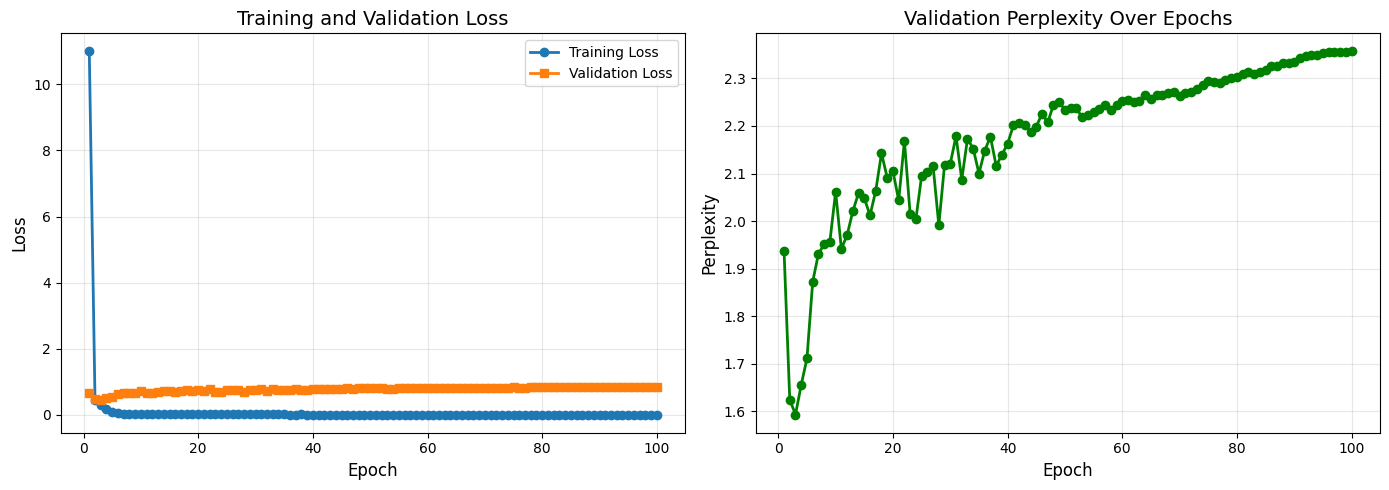


Manual training visualization saved as 'manual_training_results.png'

Final Metrics:
  Baseline Perplexity: 49.05
  Final Val Perplexity: 2.36
  Improvement: 46.69


In [17]:
if USE_MANUAL_TRAINING:
    # Plot manual training results
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot 1: Training and Validation Loss
    axes[0].plot(training_history['epochs'], training_history['train_loss'],
                 marker='o', label='Training Loss', linewidth=2)
    axes[0].plot(training_history['epochs'], training_history['val_loss'],
                 marker='s', label='Validation Loss', linewidth=2)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title('Training and Validation Loss', fontsize=14)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Validation Perplexity
    axes[1].plot(training_history['epochs'], training_history['val_perplexity'],
                 marker='o', color='green', linewidth=2)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Perplexity', fontsize=12)
    axes[1].set_title('Validation Perplexity Over Epochs', fontsize=14)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('manual_training_results.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("\nManual training visualization saved as 'manual_training_results.png'")

    # Calculate final metrics
    print(f"\nFinal Metrics:")
    print(f"  Baseline Perplexity: {baseline_perplexity:.2f}")
    print(f"  Final Val Perplexity: {training_history['val_perplexity'][-1]:.2f}")
    print(f"  Improvement: {baseline_perplexity - training_history['val_perplexity'][-1]:.2f}")
else:
    print("Skipping manual training visualization (USE_MANUAL_TRAINING=False)")

## 5B. SFTTrainer Method (Recommended - More Efficient)

This is the recommended approach using HuggingFace's SFTTrainer, which handles the training loop efficiently. This is what professionals use in production.

In [18]:
if not USE_MANUAL_TRAINING:
    # Training arguments
    training_args = TrainingArguments(
        output_dir="./results",
        num_train_epochs=3,
        per_device_train_batch_size=4,
        per_device_eval_batch_size=4,
        gradient_accumulation_steps=2,
        learning_rate=2e-4,
        warmup_steps=50,
        logging_steps=10,
        eval_strategy="steps",
        eval_steps=50,
        save_steps=100,
        save_total_limit=2,
        fp16=True,
        optim="paged_adamw_8bit",
        lr_scheduler_type="cosine",
        report_to="none",
        max_grad_norm=0.3,
        load_best_model_at_end=True,
    )

    print("Training configuration:")
    print(f"  Epochs: {training_args.num_train_epochs}")
    print(f"  Batch size: {training_args.per_device_train_batch_size}")
    print(f"  Learning rate: {training_args.learning_rate}")
    print(f"  Gradient accumulation: {training_args.gradient_accumulation_steps}")
else:
    print("Skipping SFTTrainer configuration (USE_MANUAL_TRAINING=True)")

Skipping SFTTrainer configuration (USE_MANUAL_TRAINING=True)


In [19]:
if not USE_MANUAL_TRAINING:
    # Initialize trainer
    trainer = SFTTrainer(
        model=model,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        peft_config=peft_config,
        dataset_text_field="formatted_text",
        max_seq_length=512,
        tokenizer=tokenizer,
        args=training_args,
    )

    print("Trainer initialized. Ready to train!")
else:
    print("Skipping SFTTrainer initialization (USE_MANUAL_TRAINING=True)")

Skipping SFTTrainer initialization (USE_MANUAL_TRAINING=True)


In [20]:
if not USE_MANUAL_TRAINING:
    # Start training
    print("Starting training...\n")
    trainer.train()
    print("\nTraining complete!")
else:
    print("Skipping SFTTrainer training (USE_MANUAL_TRAINING=True)")

Skipping SFTTrainer training (USE_MANUAL_TRAINING=True)


In [21]:
if not USE_MANUAL_TRAINING:
    # Save the finetuned model
    trainer.model.save_pretrained("./finetuned_cooking_model")
    tokenizer.save_pretrained("./finetuned_cooking_model")
    print("Model saved to ./finetuned_cooking_model")
else:
    print("Model already saved in manual training section")

Model already saved in manual training section


## 6. Post-Training Evaluation

In [22]:
# Calculate post-training perplexity
print("Calculating post-training perplexity...")
finetuned_perplexity, finetuned_loss = calculate_perplexity(model, val_dataset, tokenizer)

print(f"\n{'='*50}")
print("EVALUATION RESULTS")
print(f"{'='*50}")
print(f"Baseline Perplexity:   {baseline_perplexity:.2f}")
print(f"Finetuned Perplexity:  {finetuned_perplexity:.2f}")
print(f"Improvement:           {baseline_perplexity - finetuned_perplexity:.2f} ({((baseline_perplexity - finetuned_perplexity) / baseline_perplexity * 100):.1f}%)")
print(f"\nBaseline NLL Loss:     {baseline_loss:.4f}")
print(f"Finetuned NLL Loss:    {finetuned_loss:.4f}")
print(f"Loss Reduction:        {baseline_loss - finetuned_loss:.4f}")
print(f"{'='*50}")

Calculating post-training perplexity...

EVALUATION RESULTS
Baseline Perplexity:   49.05
Finetuned Perplexity:  19.76
Improvement:           29.30 (59.7%)

Baseline NLL Loss:     3.8929
Finetuned NLL Loss:    2.9834
Loss Reduction:        0.9094


In [23]:
if not USE_MANUAL_TRAINING:
    # Plot training history
    train_history = trainer.state.log_history

    # Extract losses
    train_losses = [x['loss'] for x in train_history if 'loss' in x]
    eval_losses = [x['eval_loss'] for x in train_history if 'eval_loss' in x]
    train_steps = [x['step'] for x in train_history if 'loss' in x]
    eval_steps = [x['step'] for x in train_history if 'eval_loss' in x]

    plt.figure(figsize=(12, 5))

    # Plot 1: Training and validation loss
    plt.subplot(1, 2, 1)
    plt.plot(train_steps, train_losses, label='Training Loss', alpha=0.7)
    plt.plot(eval_steps, eval_losses, label='Validation Loss', marker='o')
    plt.xlabel('Steps')
    plt.ylabel('Loss')
    plt.title('Training Progress')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # Plot 2: Perplexity comparison
    plt.subplot(1, 2, 2)
    plt.bar(['Baseline', 'Finetuned'], [baseline_perplexity, finetuned_perplexity], color=['#ff7f0e', '#2ca02c'])
    plt.ylabel('Perplexity')
    plt.title('Perplexity Comparison')
    plt.grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig('training_results.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("Training visualization saved as 'training_results.png'")
else:
    print("Visualization already created in manual training section")

Visualization already created in manual training section


## 7. Human Evaluation - Interactive Testing

In [24]:
# Function to generate responses
def generate_response(model, tokenizer, question: str, max_length: int = 256) -> str:
    """Generate a response to a cooking-related question."""
    prompt = f"<s>[INST] {question} [/INST]"

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_length,
            temperature=0.7,
            top_p=0.9,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id,
        )

    response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    # Extract only the response part (after [/INST])
    response = response.split("[/INST]")[-1].strip()

    return response

In [25]:
# Test questions for human evaluation
test_questions = [
    "How do I make a perfect risotto?",
    "What's the best way to cook salmon?",
    "Can I substitute butter with oil in baking?",
    "How long should I marinate chicken?",
    "What temperature should I bake cookies at?",
]

print("="*80)
print("HUMAN EVALUATION - Sample Interactions")
print("="*80)

for i, question in enumerate(test_questions, 1):
    print(f"\n{'='*80}")
    print(f"Question {i}: {question}")
    print(f"{'-'*80}")

    response = generate_response(model, tokenizer, question)
    print(f"Answer: {response}")
    print(f"{'='*80}")

HUMAN EVALUATION - Sample Interactions

Question 1: How do I make a perfect risotto?
--------------------------------------------------------------------------------
Answer: 1) Use high-quality arborio or carnaroli rice, which has the perfect starch content for creamy risotto. 2) Start with cold stock and risotto rice in a wide pan. 3) Add butter and olive oil to the pan, then add finely chopped onions and cook until translucent. 4) Deglaze with white wine and let it absorb completely. 5) Start adding the hot stock 1/2 cup at a time, stirring constantly and waiting for each addition to be absorbed before adding more. 6) Cook for about 18-20 minutes until the rice is al dente. 7) Finish with butter and parmesan cheese. 8) Season with salt and pepper. 9) Serve immediately while hot and creamy.

Question 2: What's the best way to cook salmon?
--------------------------------------------------------------------------------
Answer: 1) Pat salmon dry with paper towels. 2) Season both sides w

## 7.5 RAG-Enhanced Response Generation

Combine retrieval with generation for more accurate and detailed responses.

In [26]:
# RAG-enhanced generation function
def generate_response_with_rag(model, tokenizer, question: str, top_k: int = 3, max_length: int = 256) -> tuple:
    """
    Generate response using RAG: Retrieve relevant knowledge first, then generate.

    Args:
        model: Finetuned model
        tokenizer: Tokenizer
        question: User's question
        top_k: Number of knowledge pieces to retrieve
        max_length: Maximum response length

    Returns:
        tuple: (response, retrieved_knowledge)
    """
    # Step 1: Retrieve relevant knowledge
    retrieved_knowledge, distances = retrieve_relevant_knowledge(question, top_k=top_k)

    # Step 2: Create context from retrieved knowledge
    context = "\n\n".join([f"Knowledge {i+1}: {text[:300]}..." for i, text in enumerate(retrieved_knowledge)])

    # Step 3: Create prompt with context
    prompt = f"""<s>[INST] Based on the following cooking knowledge, answer the question:

{context}

Question: {question}

Provide a detailed and accurate answer based on the knowledge above. [/INST]"""

    # Step 4: Generate response
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_length,
            temperature=0.7,
            top_p=0.9,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id,
        )

    response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    response = response.split("[/INST]")[-1].strip()

    return response, retrieved_knowledge

print("RAG-enhanced generation function ready!")

RAG-enhanced generation function ready!


In [27]:
# Compare standard generation vs RAG-enhanced generation
comparison_questions = [
    "How do I make perfect risotto?",
    "What's the best way to caramelize onions?",
    "How do I prevent my scrambled eggs from being watery?",
]

print("="*80)
print("COMPARISON: Standard Generation vs RAG-Enhanced Generation")
print("="*80)

for i, question in enumerate(comparison_questions, 1):
    print(f"\n{'='*80}")
    print(f"Question {i}: {question}")
    print(f"{'='*80}")

    # Standard generation
    print(f"\n📝 STANDARD GENERATION (No RAG):")
    print(f"{'-'*80}")
    standard_response = generate_response(model, tokenizer, question, max_length=200)
    print(standard_response)

    # RAG-enhanced generation
    print(f"\n🔍 RAG-ENHANCED GENERATION (With Retrieval):")
    print(f"{'-'*80}")
    rag_response, retrieved = generate_response_with_rag(model, tokenizer, question, top_k=2, max_length=200)
    print(rag_response)

    print(f"\n📚 Retrieved Knowledge Sources:")
    for j, text in enumerate(retrieved, 1):
        print(f"  {j}. {text[:150]}...")

    print(f"\n{'='*80}")

COMPARISON: Standard Generation vs RAG-Enhanced Generation

Question 1: How do I make perfect risotto?

📝 STANDARD GENERATION (No RAG):
--------------------------------------------------------------------------------
1) Use high-quality rice (Carnaroli or Arborio). 2) Start with cold stock and keep warm. 3) Sauté onions in butter and oil until translucent. 4) Add rice and toast for 2-3 minutes, stirring constantly until grains are slightly translucent at edges. 5) Deglaze with white wine and let reduce by half. 6) Add warm stock 1/2 cup at a time, stirring constantly and waiting for each addition to be absorbed before adding more. 7) Cook for 18-20 minutes until rice is al dente. 8) Finish with butter and Parmigiano-Reggiano cheese. Patience is key!

🔍 RAG-ENHANCED GENERATION (With Retrieval):
--------------------------------------------------------------------------------
To make perfect risotto, start with high-quality arborio or carnaroli rice. Heat chicken or vegetable stock in a s

In [28]:
# Interactive RAG-powered chat
def chat_with_rag(use_rag: bool = True):
    """
    Interactive chat with optional RAG enhancement.

    Args:
        use_rag: Whether to use RAG (retrieval) or not
    """
    mode = "RAG-Enhanced" if use_rag else "Standard"
    print("\n" + "="*80)
    print(f"Interactive Cooking Assistant Chat ({mode} Mode)")
    print("Type 'quit' or 'exit' to end the conversation")
    print("Type 'toggle' to switch between RAG and Standard mode")
    print("="*80 + "\n")

    current_use_rag = use_rag

    while True:
        question = input("You: ").strip()

        if question.lower() in ['quit', 'exit', 'q']:
            print("\nGoodbye! Happy cooking!")
            break

        if question.lower() == 'toggle':
            current_use_rag = not current_use_rag
            mode = "RAG-Enhanced" if current_use_rag else "Standard"
            print(f"\n✓ Switched to {mode} mode\n")
            continue

        if not question:
            continue

        print("\nAssistant: ", end="")

        if current_use_rag:
            response, retrieved = generate_response_with_rag(model, tokenizer, question, top_k=2)
            print(response)
            print(f"\n💡 [Based on {len(retrieved)} retrieved knowledge sources]")
        else:
            response = generate_response(model, tokenizer, question)
            print(response)

        print()

# Uncomment to start RAG-enhanced interactive chat
chat_with_rag(use_rag=True)


Interactive Cooking Assistant Chat (RAG-Enhanced Mode)
Type 'quit' or 'exit' to end the conversation
Type 'toggle' to switch between RAG and Standard mode

You: maggie

Assistant: For roasting chicken, use rosemary and thyme. Cut evenly sized potatoes (Russet or Yukon Gold) and boil in cold salted water. Drain well and let steam dry 2 minutes. Mash or rice while hot. Heat butter and milk/cream before adding. Don't overmix or they get gluey. Use a potato ricer for fluffiest texture. Season well with salt and pepper. Roast chicken at 425-450°F, turning once. Internal temp to reach: 165°F (74°C). Estimated cook time: 45-60 minutes.

💡 [Based on 2 retrieved knowledge sources]

You: how to make chicken sandwich

Assistant: For a crispy chicken sandwich: 1) Follow the steps in Knowledge 2 to prepare the chicken. 2) Heat oil in pan over medium-high. 3) Place skin-side down, press gently. 4) Cook 2-3 minutes without moving. 5) Flip and cook 2-3 minutes more. 6) Internal temp should reach 165°

## 7.8 RAG Evaluation Metrics

Evaluate the quality of retrieval and impact on generation.

In [29]:
# Evaluate retrieval quality
def evaluate_retrieval_quality(test_queries: List[str], top_k: int = 3):
    """
    Evaluate how well the RAG system retrieves relevant information.
    """
    print("Evaluating RAG Retrieval Quality...")
    print("="*80)

    retrieval_scores = []

    for query in test_queries:
        retrieved, distances = retrieve_relevant_knowledge(query, top_k=top_k)

        # Calculate average distance (lower is better)
        avg_distance = np.mean(distances)
        retrieval_scores.append(avg_distance)

        print(f"\nQuery: {query}")
        print(f"  Average retrieval distance: {avg_distance:.4f}")
        print(f"  Top match distance: {distances[0]:.4f}")

    print(f"\n{'='*80}")
    print("Overall Retrieval Statistics:")
    print(f"  Mean distance: {np.mean(retrieval_scores):.4f}")
    print(f"  Std distance: {np.std(retrieval_scores):.4f}")
    print(f"  Min distance: {np.min(retrieval_scores):.4f}")
    print(f"  Max distance: {np.max(retrieval_scores):.4f}")
    print("  (Lower distances indicate better retrieval)")

    return retrieval_scores

# Test queries for evaluation
eval_queries = [
    "How to make risotto?",
    "Best temperature for baking cookies?",
    "How to caramelize onions?",
    "Tips for cooking salmon?",
    "How to prevent pasta from sticking?",
    "What's the secret to fluffy mashed potatoes?",
    "How to properly season cast iron?",
    "Best way to store fresh herbs?",
]

scores = evaluate_retrieval_quality(eval_queries, top_k=3)

Evaluating RAG Retrieval Quality...

Query: How to make risotto?
  Average retrieval distance: 0.9164
  Top match distance: 0.5303

Query: Best temperature for baking cookies?
  Average retrieval distance: 0.7346
  Top match distance: 0.3824

Query: How to caramelize onions?
  Average retrieval distance: 0.9091
  Top match distance: 0.7451

Query: Tips for cooking salmon?
  Average retrieval distance: 0.9657
  Top match distance: 0.5203

Query: How to prevent pasta from sticking?
  Average retrieval distance: 1.0142
  Top match distance: 0.7713

Query: What's the secret to fluffy mashed potatoes?
  Average retrieval distance: 0.9831
  Top match distance: 0.8083

Query: How to properly season cast iron?
  Average retrieval distance: 1.1155
  Top match distance: 1.0403

Query: Best way to store fresh herbs?
  Average retrieval distance: 0.9400
  Top match distance: 0.5385

Overall Retrieval Statistics:
  Mean distance: 0.9473
  Std distance: 0.1013
  Min distance: 0.7346
  Max distance: 

In [30]:
# Compare response quality: Standard vs RAG
def compare_generation_quality(test_prompts: List[str]):
    """
    Generate responses with and without RAG, compare them.
    """
    print("Comparing Standard vs RAG-Enhanced Generation...")
    print("="*80)

    for prompt in test_prompts:
        print(f"\n{'='*80}")
        print(f"Prompt: {prompt}")
        print(f"{'='*80}")

        # Standard generation
        print("\n[STANDARD RESPONSE]")
        standard_response = generate_response(model, tokenizer, question=prompt, max_length=150)
        print(standard_response)

        # RAG-enhanced generation
        print("\n[RAG-ENHANCED RESPONSE]")
        rag_response, _ = generate_response_with_rag(model, tokenizer, question=prompt, max_length=150, top_k=3)
        print(rag_response)

        print(f"\n{'-'*80}")
        print(f"Standard length: {len(standard_response)} chars")
        print(f"RAG length: {len(rag_response)} chars")

# Test prompts for comparison
comparison_prompts = [
    "What's the best way to cook risotto?",
    "How do I prevent my cookies from spreading?",
    "Tips for perfectly caramelized onions?",
]

compare_generation_quality(comparison_prompts)


Comparing Standard vs RAG-Enhanced Generation...

Prompt: What's the best way to cook risotto?

[STANDARD RESPONSE]
For perfect risotto, follow these steps: 1) Use high-quality arborio or carnaroli rice, which has the right starch content for creamy texture. 2) Start with cold stock and risotto rice in a wide pan. 3) Add butter and olive oil to the pan, then add the rice and toast it for 2-3 minutes, stirring constantly until the grains are slightly translucent at the edges. 4) Deglaze with white wine and let it absorb completely. 5) Start adding warm stock one ladle at a time, stirring constantly and waiting for each addition to be absorbed before adding more. 6) Cook the risotto for about 1

[RAG-ENHANCED RESPONSE]
For authentic risotto, start with high-quality arborio or carnaroli rice. Heat chicken or vegetable stock in a separate pot and keep warm. In a wide, heavy-bottomed pan, sauté finely chopped onions in butter and olive oil until translucent. Add the rice and toast it for 2-

✓ Saved RAG metrics visualization to 'rag_metrics.png'


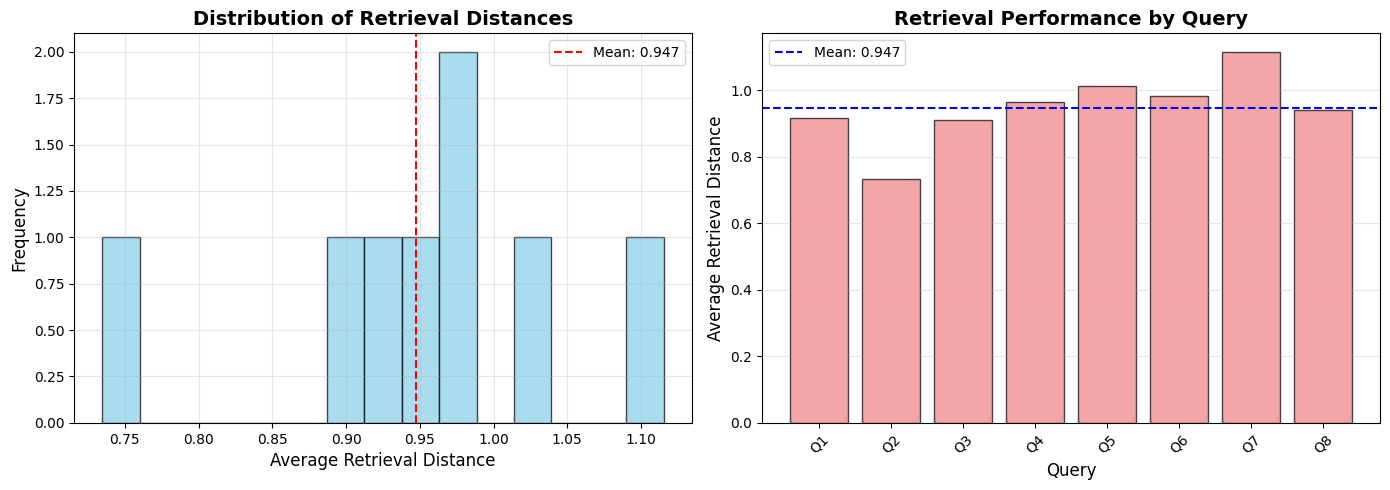

In [31]:
# Visualize retrieval performance
import matplotlib.pyplot as plt

def visualize_rag_metrics(retrieval_scores: List[float]):
    """
    Create visualizations for RAG performance metrics.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot 1: Retrieval distance distribution
    axes[0].hist(retrieval_scores, bins=15, color='skyblue', edgecolor='black', alpha=0.7)
    axes[0].set_xlabel('Average Retrieval Distance', fontsize=12)
    axes[0].set_ylabel('Frequency', fontsize=12)
    axes[0].set_title('Distribution of Retrieval Distances', fontsize=14, fontweight='bold')
    axes[0].axvline(np.mean(retrieval_scores), color='red', linestyle='--',
                    label=f'Mean: {np.mean(retrieval_scores):.3f}')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Query-by-query retrieval performance
    query_labels = [f"Q{i+1}" for i in range(len(retrieval_scores))]
    axes[1].bar(query_labels, retrieval_scores, color='lightcoral', edgecolor='black', alpha=0.7)
    axes[1].set_xlabel('Query', fontsize=12)
    axes[1].set_ylabel('Average Retrieval Distance', fontsize=12)
    axes[1].set_title('Retrieval Performance by Query', fontsize=14, fontweight='bold')
    axes[1].axhline(np.mean(retrieval_scores), color='blue', linestyle='--',
                    label=f'Mean: {np.mean(retrieval_scores):.3f}')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='y')
    axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('rag_metrics.png', dpi=150, bbox_inches='tight')
    print("✓ Saved RAG metrics visualization to 'rag_metrics.png'")
    plt.show()

# Visualize the retrieval scores
visualize_rag_metrics(scores)

## 2.6 Save RAG Components for Reuse

To avoid rebuilding embeddings every time, save the FAISS index and embeddings to disk.

In [32]:
import os

# Save RAG components
def save_rag_components(embeddings, index, save_dir='rag_components'):
    """Save FAISS index and embeddings for later reuse."""
    os.makedirs(save_dir, exist_ok=True)

    # Save embeddings
    np.save(os.path.join(save_dir, 'knowledge_embeddings.npy'), embeddings)
    print(f"✓ Saved embeddings to {save_dir}/knowledge_embeddings.npy")

    # Save FAISS index
    faiss.write_index(index, os.path.join(save_dir, 'knowledge_index.faiss'))
    print(f"✓ Saved FAISS index to {save_dir}/knowledge_index.faiss")

    print(f"\n✓ RAG components saved successfully to '{save_dir}/' directory")

# Load RAG components
def load_rag_components(save_dir='rag_components'):
    """Load previously saved FAISS index and embeddings."""
    embeddings_path = os.path.join(save_dir, 'knowledge_embeddings.npy')
    index_path = os.path.join(save_dir, 'knowledge_index.faiss')

    if not os.path.exists(embeddings_path) or not os.path.exists(index_path):
        print(f"✗ RAG components not found in '{save_dir}/'")
        return None, None

    # Load embeddings
    embeddings = np.load(embeddings_path)
    print(f"✓ Loaded embeddings from {embeddings_path}")

    # Load FAISS index
    index = faiss.read_index(index_path)
    print(f"✓ Loaded FAISS index from {index_path}")

    print(f"\n✓ RAG components loaded successfully from '{save_dir}/' directory")
    return embeddings, index

# Save the RAG components we just created
save_rag_components(knowledge_embeddings, index)

✓ Saved embeddings to rag_components/knowledge_embeddings.npy
✓ Saved FAISS index to rag_components/knowledge_index.faiss

✓ RAG components saved successfully to 'rag_components/' directory


In [33]:
# Interactive chat mode
def chat():
    """Interactive chat with the finetuned model."""
    print("\n" + "="*80)
    print("Interactive Cooking Assistant Chat")
    print("Type 'quit' or 'exit' to end the conversation")
    print("="*80 + "\n")

    while True:
        question = input("You: ").strip()

        if question.lower() in ['quit', 'exit', 'q']:
            print("\nGoodbye! Happy cooking!")
            break

        if not question:
            continue

        print("\nAssistant: ", end="")
        response = generate_response(model, tokenizer, question)
        print(response + "\n")

# Uncomment to start interactive chat
chat()


Interactive Cooking Assistant Chat
Type 'quit' or 'exit' to end the conversation

You: chicken fry

Assistant: Per pound: 1) 1/4 cup cornstarch (for crispiness). 2) 2 tablespoons buttermilk. 3) 1 egg. 4) 1/4 cup flour. 5) 1/4 teaspoon baking soda. 6) Salt and pepper. Mix dry ingredients together, whisk in wet ingredients. Dip chicken pieces in mixture, coat evenly. Let sit 30 minutes in refrigerator. Fry at 350-375°F, turning halfway through, 12-15 minutes total. Internal temp should reach 165°F. The coating should be dry to the touch. Don't overcrowd when frying or temperature drops. Fry in batches if needed. The breading should adhere well to the chicken.

You: bread toast

Assistant: Pan-searing is excellent: 1) Pat salmon dry. 2) Heat pan over medium-high. 3) Add 1-2 tablespoons oil, swirling to coat. 4) Place skin-side down, press gently. 5) Cook 4-5 minutes without moving. 6) Flip and cook 2-3 minutes more. 7) Remove from pan and let rest 5 minutes. 8) Serve with lemon butter. T

## 8. Save Evaluation Results

In [34]:
# Save evaluation metrics

if USE_MANUAL_TRAINING:
    # Use parameters from manual training
    epochs = NUM_EPOCHS
    batch_size = BATCH_SIZE
    learning_rate = LEARNING_RATE
else:
    # Use parameters from SFTTrainer (if it was used)
    epochs = training_args.num_train_epochs
    batch_size = training_args.per_device_train_batch_size
    learning_rate = training_args.learning_rate

results = {
    "baseline": {
        "perplexity": float(baseline_perplexity),
        "nll_loss": float(baseline_loss)
    },
    "finetuned": {
        "perplexity": float(finetuned_perplexity),
        "nll_loss": float(finetuned_loss)
    },
    "improvement": {
        "perplexity_reduction": float(baseline_perplexity - finetuned_perplexity),
        "perplexity_reduction_pct": float((baseline_perplexity - finetuned_perplexity) / baseline_perplexity * 100),
        "loss_reduction": float(baseline_loss - finetuned_loss)
    },
    "training_config": {
        "epochs": epochs,
        "batch_size": batch_size,
        "learning_rate": learning_rate,
        "manual_training_used": USE_MANUAL_TRAINING
    }
}

# Optionally, save these results to a JSON file
output_filename = "evaluation_results.json"
with open(output_filename, 'w') as f:
    json.dump(results, f, indent=4)

print(f"Evaluation results saved to {output_filename}")

Evaluation results saved to evaluation_results.json
